# Random Forest 

This notebook trains a Random Forest model to predict the death risk of leukemia patients from clinical and molecular data.


The objective is therefore twofold:
1. Evaluate the ability of Random Forest to classify patients according to their risk.
2. Analyze the quality of its probabilities before any calibration.


In [2]:
import sys
import pandas as pd
import numpy as np
import os
import importlib
from src.eval_utils import full_evaluation
from src.modeltrainer import *
import matplotlib.pyplot as plt
import glob

# Reimporter les modules pour refléter les modifications
importlib.reload(sys.modules['src.eval_utils'])
importlib.reload(sys.modules['src.modeltrainer'])

sys.path.insert(0, './src')

Loading processed data

The data has been preprocessed in previous notebooks and is now loaded in the form:
- train
- test



In [ ]:
# =============================================================================
# CELLULE 1 : IMPORT DES DONNÉES
# =============================================================================


# Configuration
DATA_PATH = 'data/processed_data_imputed.xlsx'
COLS_TO_DROP = ['patient_ids', 'feat_40', 'feat_82']

# Chargement des données
print("📂 Chargement des données...")

train_data = pd.read_excel(DATA_PATH, sheet_name='train')
cal_data = pd.read_excel(DATA_PATH, sheet_name='calibration')
test_data = pd.read_excel(DATA_PATH, sheet_name='test')

# Séparation features / target
X_train = train_data.iloc[:, :-1].drop(columns=COLS_TO_DROP, errors='ignore')
y_train = train_data.iloc[:, -1]

X_test = test_data.iloc[:, :-1].drop(columns=COLS_TO_DROP, errors='ignore')
y_test = test_data.iloc[:, -1]

print(f"✓ Données chargées:")
print(f"   - Train: {X_train.shape[0]} lignes, {X_train.shape[1]} features")
print(f"   - Test: {X_test.shape[0]} lignes")
print(f"   - Target distribution (train): {y_train.value_counts().to_dict()}")

📂 Chargement des données...
✓ Données chargées:
   - Train: 83555 lignes, 81 features
   - Calibration: 28381 lignes
   - Test: 28465 lignes
   - Target distribution (train): {0: 46672, 1: 36883}


We check if the trained model doesn't already exist, if it does we load it otherwise we train it.

In [4]:
# =============================================================================
# CELLULE 2 : CHARGEMENT OU ENTRAÎNEMENT DU MODÈLE RandomForest
# =============================================================================


# Configuration
MODEL_DIR = 'models'
MODEL_TYPE = 'RandomForest'  # 'LogisticRegression', 'RandomForest', 'XGBoost'



# Initialiser le trainer
trainer = ModelML(
    x_train=X_train,
    x_test=X_test,
    y_train=y_train,
    y_test=y_test
)

# Chercher un modèle existant
existing_model = find_existing_model(MODEL_DIR, MODEL_TYPE)

if existing_model:
    print(f"📦 Modèle existant trouvé: {existing_model}")
    trainer.load_model(existing_model)
else:
    print(f"🔄 Aucun modèle {MODEL_TYPE} trouvé. Entraînement en cours...")
    
    trainer.tune_random_forest(
        param_grid={
            'n_estimators': [50, 100, 200],
            'max_depth': [3, 5, 10, None],
            'min_samples_leaf': [1, 2],
            'max_features': ['sqrt']
        },
        method='random',
        n_iter=20,
        cv=5,
        scoring='roc_auc'
    )
    
    trainer.save_model()
    print(f"✓ Modèle entraîné et sauvegardé")

print(f"\n📊 Modèle actif: {trainer.model_name}")
print(f"   Paramètres: {trainer.best_params}")

🔄 Aucun modèle RandomForest trouvé. Entraînement en cours...

🔍 Recherche d'hyperparamètres (RANDOM)
   Modèle: random_forest_tuned
   Scoring: roc_auc
   CV folds:  5
   Paramètres testés: ['n_estimators', 'max_depth', 'min_samples_leaf', 'max_features']
Fitting 5 folds for each of 20 candidates, totalling 100 fits


/home/mouad-sehli/datascience/lib/python3.12/site-packages/joblib/externals/loky/process_executor.py:782: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(



✓ Meilleurs paramètres trouvés:
   - n_estimators:  200
   - min_samples_leaf:  1
   - max_features:  sqrt
   - max_depth:  None
   - Best CV Score (roc_auc): 0.9572

📊 Résultats:
   - Train Accuracy: 1.0000
   - Test Accuracy:  0.7096
✓ Modèle sauvegardé: models/random_forest_tuned.pkl
✓ Paramètres sauvegardés: models/random_forest_tuned_params.json
✓ Modèle entraîné et sauvegardé

📊 Modèle actif: random_forest_tuned
   Paramètres: {'n_estimators': 200, 'min_samples_leaf': 1, 'max_features': 'sqrt', 'max_depth': None}



📊 ÉVALUATION SUR LE TEST SET

🔍 ÉVALUATION COMPLÈTE:  random_forest_tuned_test
📊 MÉTRIQUES D'ÉVALUATION

🎯 Métriques de Classification:
----------------------------------------
   Accuracy                 : 0.7096
   Balanced_Accuracy        : 0.7031
   Precision                : 0.6987
   Recall_Sensitivity       : 0.6333
   Specificity              : 0.7730
   F1_Score                 : 0.6644
   Matthews_Corr_Coef       : 0.4111
   Cohen_Kappa              : 0.4095

📈 Métriques Probabilistes:
----------------------------------------
   ROC_AUC                  : 0.7790
   PR_AUC                   : 0.7340
   Brier_Score              : 0.1915
   Log_Loss                 : 0.5648

📋 RAPPORT DE CLASSIFICATION
              precision    recall  f1-score   support

    Classe 0       0.72      0.77      0.74     15543
    Classe 1       0.70      0.63      0.66     12922

    accuracy                           0.71     28465
   macro avg       0.71      0.70      0.70     28465
weighted

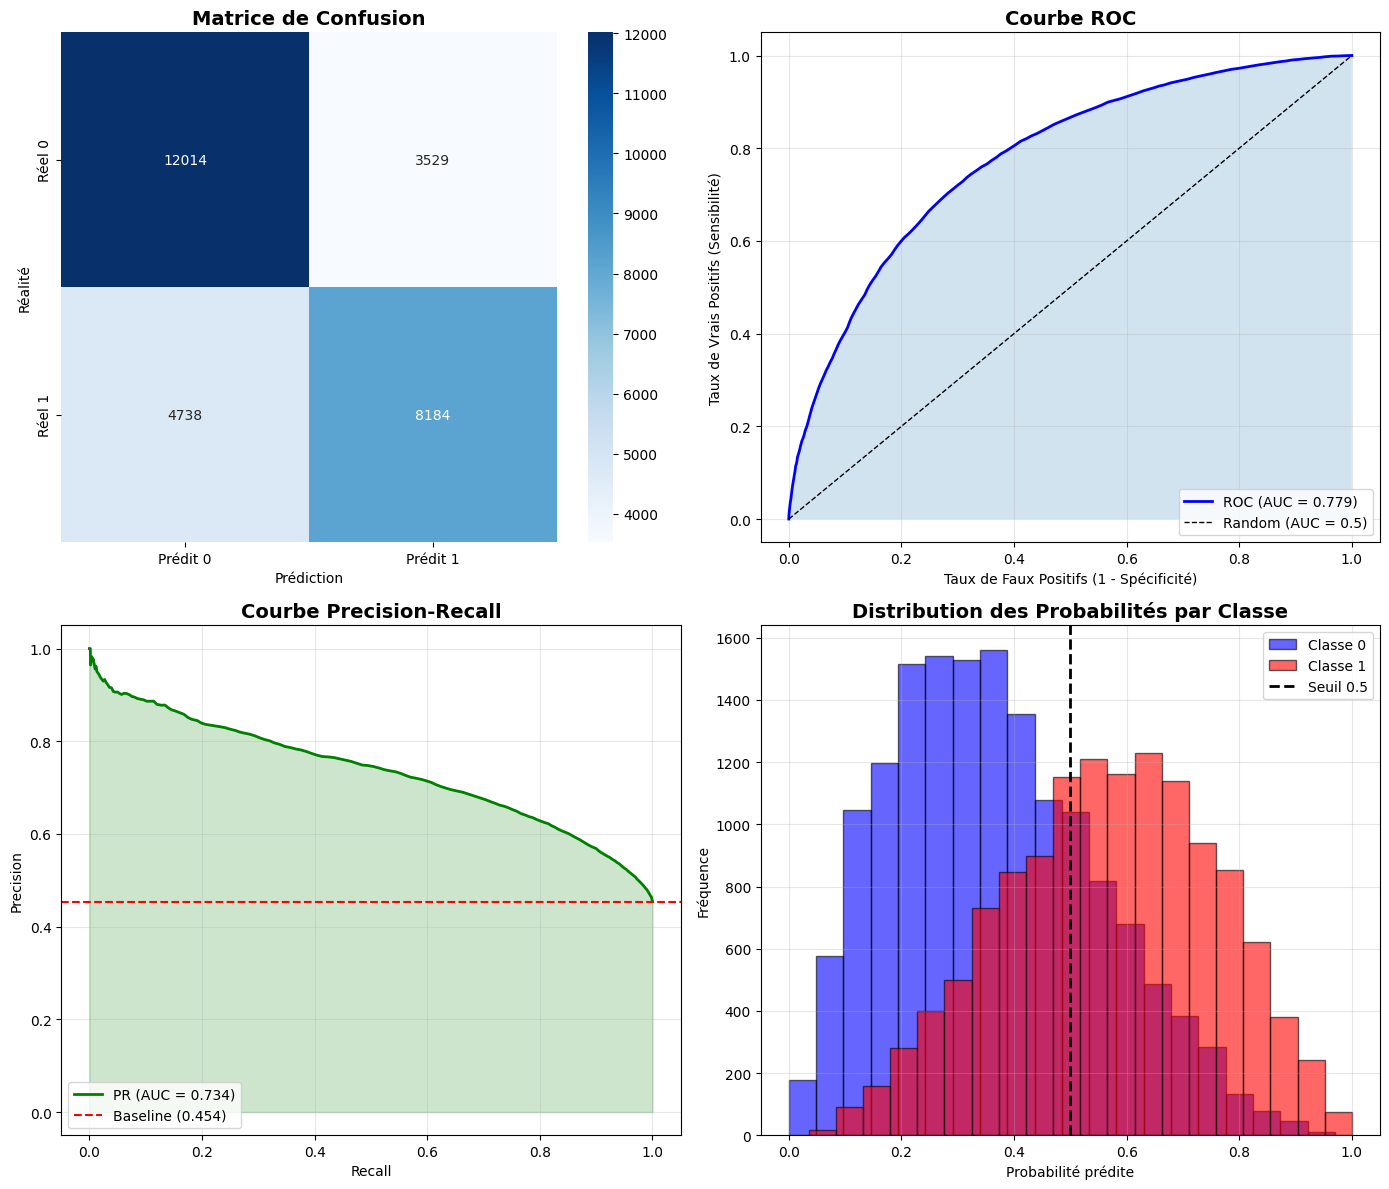

In [5]:
# =============================================================================
# CELLULE 3 : ÉVALUATION COMPLÈTE SUR LE TEST SET
# =============================================================================

# --- Évaluation sur le TEST SET ---
print("\n" + "="*70)
print("📊 ÉVALUATION SUR LE TEST SET")
print("="*70)

y_pred_test = trainer.predict(X_test)
y_proba_test = trainer.predict_proba(X_test)[:, 1]

metrics_test = full_evaluation(
    y_true=y_test,
    y_pred=y_pred_test,
    y_proba=y_proba_test,
    model_name=f"{trainer.model_name}_test",
    save_dir='results'
)

# Afficher les plots
plt.show()

##  Random Forest Results Analysis

### Model Performance
- **ROC-AUC: 0.779** — **Best discriminative capacity** among all models
- **Accuracy: 71.0%** — Highest performance
- **Brier Score: 0.192** — Excellent, close to logistic regression
- **Log Loss: 0.565** — The best log loss score


Random Forest combines excellent discrimination (high AUC) with relatively well-calibrated probabilities.

Random forests tend to produce probabilities compressed toward 0.5 (tree averaging effect). The calibration curve will probably show an "S" shape.

Random Forest is the best overall model before calibration, offering the best compromise between discrimination and calibration. Post-hoc calibration will correct the slight bias toward average probabilities.